# 🗣️ Citizen Voice: AI analyst for UAE government app reviews
**MAAI902 Natural Language Processing & LLMs · Individual project**

Millions of residents use UAE government apps (UAE PASS, DubaiNow, RTA, DEWA, ICP, TAMM) and leave reviews in
**English and Arabic**. Nobody can read them all. Citizen Voice collects reviews automatically and answers three
questions for a government digital-services team: **what is broken, how upset people are, and what to fix first.**

**Alignment:** UAE National AI Strategy 2031, *Smart Government* priority (lecture 3), with Arabic-first resources
(CAMeL Tools and CAMeLBERT from NYU Abu Dhabi, multilingual BGE-M3).

| # | Section | Course concept |
|---|---|---|
| 1 | Automated data collection | data science workflow |
| 2 | Exploratory analysis | |
| 3 | English + Arabic preprocessing | tokenization, stop words, stemming, lemmatization, CAMeL normalization |
| 4 | POS + dependency parsing | POS tags, dependency parsing, Matcher, aspect extraction, relation extraction |
| 5 | N-grams | n-grams |
| 6 | Full NLP pipeline | everything below, applied to every review |
| 7 | Text representations | BoW, TF-IDF, Word2Vec, sentence embeddings (BGE-M3), similarity search, cross-lingual retrieval |
| 8 | Sentiment, 5 approaches | lexicon (VADER), ML (TF-IDF + LR), pre-trained transformers |
| 9 | Fine-tuning with LoRA | pre-training vs fine-tuning, parameter-efficient adaptation |
| 10 | Emotion / mood | emotion models, valence-arousal |
| 11 | NER + relations | spaCy NER, CAMeLBERT NER, LLM-based NER, relation extraction |
| 12 | Issue discovery | embeddings + clustering + LLM naming |
| 13 | Release regression detector | statistics on NLP outputs |
| 14 | Prompt engineering | zero-shot vs role/definitions vs few-shot |
| 15 | RAG + faithfulness check | retrieval-augmented generation, hallucination control |
| 16 | Bilingual replies + executive briefing | generation |
| 17 | Results export + launch the app | |

**Before you start:** `Runtime → Change runtime type → T4 GPU`. Add your OpenRouter key as a Colab secret named
`OPENROUTER_API_KEY` (🔑 icon on the left, enable notebook access).

## 0. Setup

In [1]:
import os, sys, glob, zipfile, subprocess
IN_COLAB = "google.colab" in sys.modules
REPO = "citizen-voice"

if os.path.basename(os.getcwd()) == REPO:
    os.chdir("..")
zips = glob.glob("citizen-voice*.zip") or glob.glob("/content/drive/MyDrive/citizen-voice*.zip")
if not zips and not os.path.exists(REPO) and IN_COLAB:
    from google.colab import files
    zips = list(files.upload().keys())
if zips:
    newest = max(zips, key=os.path.getmtime)
    zipfile.ZipFile(newest).extractall(".")
    print("Code from:", newest)
os.chdir(REPO)
sys.path.insert(0, os.getcwd())
for m in [m for m in sys.modules if m == "cvoice" or m.startswith("cvoice.")]:
    sys.modules.pop(m)
print("Working directory:", os.getcwd(), "| package found:", os.path.exists("cvoice/__init__.py"))

Saving citizen-voice (4).zip to citizen-voice (4).zip
Code from: citizen-voice (4).zip
Working directory: /content/citizen-voice | package found: True


In [2]:
def sh(cmd):
    print(">", cmd); r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print((r.stdout + r.stderr)[-600:] if r.returncode else "ok")
    return r.returncode

if IN_COLAB:
    sh(f"{sys.executable} -m pip install -q -r requirements.txt")
    sh(f"{sys.executable} -m pip install -q camel-tools")
    sh(f"{sys.executable} -m spacy download en_core_web_sm -q")
    sh(f"{sys.executable} -m pip uninstall -y -q torchao")

> /usr/bin/python3 -m pip install -q -r requirements.txt
ok
> /usr/bin/python3 -m pip install -q camel-tools
ok
> /usr/bin/python3 -m spacy download en_core_web_sm -q
ok
> /usr/bin/python3 -m pip uninstall -y -q torchao
ok


In [3]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

from cvoice import (config, collect, preprocess, linguistic, models, pipeline, evaluate, topics,
                regression, search, genai, llm, finetune)

os.makedirs("figures", exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight"); plt.show()

R = {}
sns.set_theme(style="whitegrid")
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU: slower but works)")
print("LLM key found:", llm.available(), "| CAMeL Tools:", preprocess.CAMEL_AVAILABLE)
if not llm.available():
    print("⚠️  LLM sections (cluster names, LLM NER, prompting, RAG, replies) will be skipped.\n   ", llm.key_problem())

GPU: Tesla T4
LLM key found: True | CAMeL Tools: True


## 1. Automated data collection
`cvoice/collect.py` uses `google-play-scraper` to fetch the newest reviews of each app in English and Arabic from the
UAE store (`country="ae"`). It is **incremental**: reviews already on disk are skipped, so the same command (or the
**Refresh data** button in the app) keeps the dataset up to date. Wrong package ids are fixed automatically with a
Play Store search.

**Ethics:** reviews are public, but we never store reviewer names (only a short one-way hash), and we only report
aggregates.

In [4]:
PER_LANG = config.REVIEWS_PER_LANG
raw = collect.collect(per_lang=PER_LANG)
R["n_raw"] = len(raw); R["n_apps"] = raw["app"].nunique()
print(raw.groupby(["app", "lang_requested"]).size().unstack(fill_value=0))
raw.sample(5, random_state=1)[["app", "rating", "version", "date", "text"]]

[UAE PASS]
  en: 600 new reviews
  ar: 600 new reviews
[DubaiNow]
  en: 600 new reviews
  ar: 391 new reviews
[RTA Dubai]
  en: 600 new reviews
  ar: 600 new reviews
[DEWA]
  en: 600 new reviews
  ar: 150 new reviews
[UAEICP]
  'UAEICP': id ae.gov.icp.smartservices not found, using ae.icp.wasel (Wasel ICP)
  en: 0 new reviews
  ar: 0 new reviews
[TAMM]
  could not find TAMM on the store, skipping it
[Dubai Police]
  en: 600 new reviews
  ar: 600 new reviews
[MOHRE]
  'MOHRE': id ae.gov.mohre not found, using ae.gov.mol.g2g (MOHRE G2G)
  en: 8 new reviews
  ar: 17 new reviews
Saved 5365 reviews (5366 new) to /content/citizen-voice/data/reviews.parquet
lang_requested   ar   en
app                     
DEWA            149  600
Dubai Police    600  600
DubaiNow        391  600
MOHRE            17    8
RTA Dubai       600  600
UAE PASS        600  600


,app,rating,version,date,text
1373,DubaiNow,1,None,2025-03-13 02:00:59,Please add the mParking option which was previ...
325,UAE PASS,5,6.4.3,2026-07-20 17:36:17,performance it was so beautiful
1356,DubaiNow,5,14.0.3,2025-04-16 12:50:33,good
3116,RTA Dubai,4,3.9.11,2023-01-11 15:44:19,تطبيق ماشاءالله تبارك الله
1060,UAE PASS,5,5.10.1,2025-03-24 05:54:02,تمام


## 2. Exploratory analysis

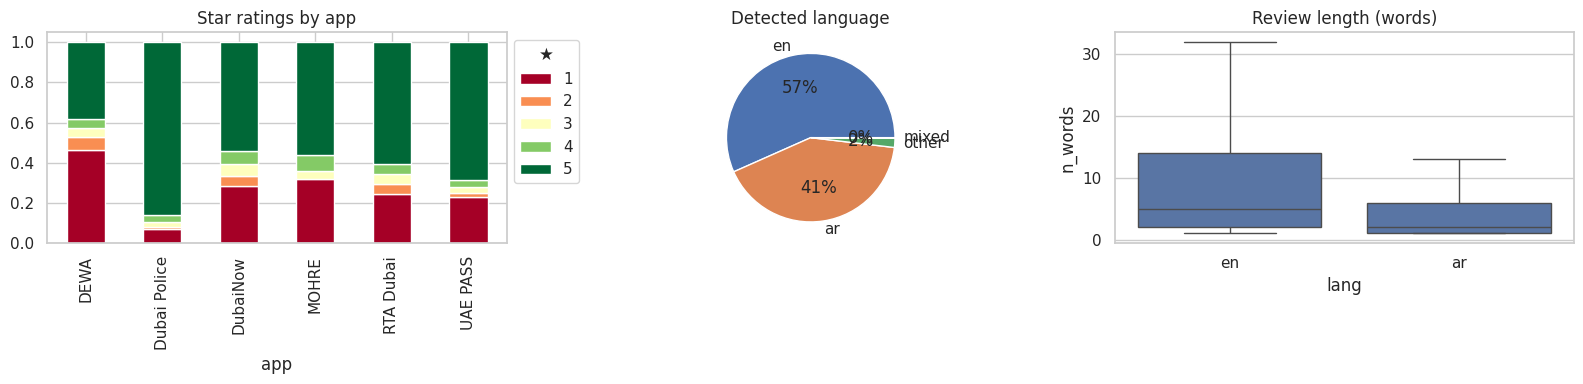

{'n_raw': 5365, 'n_apps': 6, 'avg_rating': np.float64(3.8), 'share_negative': np.float64(0.276), 'share_arabic': np.float64(0.415), 'median_words': 3}


In [5]:
raw["lang"] = raw["text"].map(preprocess.detect_lang)
raw["n_words"] = raw["text"].str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw.groupby("app")["rating"].value_counts(normalize=True).unstack().plot.bar(stacked=True, ax=ax[0], colormap="RdYlGn")
ax[0].set_title("Star ratings by app"); ax[0].legend(title="★", bbox_to_anchor=(1, 1))
raw["lang"].value_counts().plot.pie(autopct="%1.0f%%", ax=ax[1]); ax[1].set_title("Detected language"); ax[1].set_ylabel("")
sns.boxplot(data=raw[raw.lang.isin(["en", "ar"])], x="lang", y="n_words", ax=ax[2], showfliers=False)
ax[2].set_title("Review length (words)")
savefig("eda")
R["avg_rating"] = round(raw["rating"].mean(), 2)
R["share_negative"] = round((raw["rating"] <= 2).mean(), 3)
R["share_arabic"] = round((raw["lang"] == "ar").mean(), 3)
R["median_words"] = int(raw["n_words"].median())
print(R)

**What to notice:** government app reviews are **polarised**, mostly 1★ or 5★, with few 3★. That is why we
report **macro-F1** (it weights the rare *neutral* class equally) and use class weights when training.
Reviews are short (a few dozen words), so we can use `max_length=128-256` tokens everywhere.

## 3. Preprocessing: English and Arabic
Arabic needs different treatment from English:
* **Orthographic variation:** أ / إ / آ / ا are often written interchangeably, ى vs ي, ة vs ه. CAMeL Tools normalises these.
* **Diacritics (tashkeel) and tatweel (ـ)** are optional and must be removed.
* **Rich morphology and clitics:** "والتطبيق" = و + ال + تطبيق ("and the app"). Root stemmers (ISRI) are aggressive;
  light stemming only removes common prefixes and suffixes.
* **Negations must be kept** in both languages (لا، لم، لن، ما، ليس / not, never): standard stop-word lists remove
  them, which destroys sentiment.

In [6]:
en_example = "After the latest update, the app keeps crashing and I couldn't log in with Face ID!! 😡"
ar_example = "بعد التحديث الأخير، التطبيقُ لا يعمل والبصمة لم تَعُد تعمل ابداااً 😡"
for t in (en_example, ar_example):
    info = preprocess.explain(t)
    print(f"\nLANGUAGE: {info['language']}")
    for k in ["cleaned", "tokens", "without_stopwords", "stems", "lemmas"]:
        print(f"  {k:18}: {info[k]}")


LANGUAGE: en
  cleaned           : after the latest update, the app keeps crashing and i couldn't log in with face id!! emoji_enraged_face
  tokens            : ['after', 'the', 'latest', 'update', 'the', 'app', 'keeps', 'crashing', 'and', 'i', 'could', 'not', 'log', 'in', 'with', 'face', 'id', 'emoji_enraged_face']
  without_stopwords : ['latest', 'update', 'app', 'keeps', 'crashing', 'could', 'not', 'log', 'face', 'id', 'emoji_enraged_face']
  stems             : ['latest', 'updat', 'app', 'keep', 'crash', 'could', 'not', 'log', 'face', 'id', 'emoji_enraged_fac']
  lemmas            : ['latest', 'update', 'app', 'keep', 'crash', 'could', 'not', 'log', 'face', 'id', 'emoji_enraged_face']

LANGUAGE: ar
  cleaned           : بعد التحديث الاخير، التطبيق لا يعمل والبصمه لم تعد تعمل ابداا emoji_enraged_face
  tokens            : ['بعد', 'التحديث', 'الاخير', '،', 'التطبيق', 'لا', 'يعمل', 'والبصمه', 'لم', 'تعد', 'تعمل', 'ابداا']
  without_stopwords : ['التحديث', 'الاخير', 'التطبيق', 'لا', '

In [7]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer
words = ["crashing", "crashes", "verification", "updated", "payments", "renewal", "services", "unable", "easily"]
wnl = WordNetLemmatizer()
pd.DataFrame({"word": words,
              "Porter": [PorterStemmer().stem(w) for w in words],
              "Snowball": [SnowballStemmer("english").stem(w) for w in words],
              "Lancaster": [LancasterStemmer().stem(w) for w in words],
              "WordNet lemma": [wnl.lemmatize(wnl.lemmatize(w), "v") for w in words],
              "spaCy lemma": [linguistic.nlp()(w)[0].lemma_ for w in words]})

,word,Porter,Snowball,Lancaster,WordNet lemma,spaCy lemma
0,crashing,crash,crash,crash,crash,crash
1,crashes,crash,crash,crash,crash,crash
2,verification,verif,verif,ver,verification,verification
3,updated,updat,updat,upd,update,update
4,payments,payment,payment,pay,payment,payment
5,renewal,renew,renew,renew,renewal,renewal
6,services,servic,servic,serv,service,service
7,unable,unabl,unabl,un,unable,unable
8,easily,easili,easili,easy,easily,easily


In [8]:
ar_words = ["التطبيقات", "والخدمة", "إقامتي", "بالبطاقة", "مستشفى", "رائعـــة", "تَحْدِيث"]
from nltk.stem.isri import ISRIStemmer
pd.DataFrame({"word": ar_words,
              "CAMeL normalised": [preprocess.normalize_ar(w) for w in ar_words],
              "ISRI root": [ISRIStemmer().stem(preprocess.normalize_ar(w)) for w in ar_words],
              "light stem (ours)": [preprocess.light_stem_ar(preprocess.normalize_ar(w)) for w in ar_words]})

,word,CAMeL normalised,ISRI root,light stem (ours)
0,التطبيقات,التطبيقات,طبق,تطبيق
1,والخدمة,والخدمه,خدم,خدمه
2,إقامتي,اقامتي,قمت,اقامتي
3,بالبطاقة,بالبطاقه,بطق,بطاقه
4,مستشفى,مستشفي,شفي,مستشفي
5,رائعـــة,رائعه,رئع,رائعه
6,تَحْدِيث,تحديث,حدث,تحديث


In [9]:
rows = []
for lang in ["en", "ar"]:
    texts = raw[raw.lang == lang]["text"].tolist()
    for mode in ["raw", "nostop", "stem", "lemma"]:
        toks = [preprocess.tokens(t, lang, mode) for t in texts]
        rows.append({"language": lang, "step": mode, "tokens": sum(map(len, toks)),
                     "vocabulary": len(set(w for ts in toks for w in ts))})
vocab = pd.DataFrame(rows)
R["vocab"] = vocab.to_dict("records")
vocab.pivot(index="step", columns="language", values="vocabulary").loc[["raw", "nostop", "stem", "lemma"]]

language,ar,en
step,,
raw,3271,3436
nostop,3106,3294
stem,1456,2529
lemma,2644,2688


Stemming shrinks the vocabulary the most but produces non-words (ISRI turns many words into 3-letter roots,
merging unrelated meanings). For features we use **lemmas (English) and light stems (Arabic)**, a balance between
grouping variants and keeping meaning. Transformer models receive the **original text**, because their own
sub-word tokenizers were trained on raw text.

## 4. Linguistic analysis: POS tagging and dependency parsing (spaCy)
We use the dependency tree to extract **what** is wrong (the aspect) and **how** (the opinion):
* `amod`: "slow **login**" → (login, slow)
* `nsubj` + `acomp`: "the **app** is useless" → (app, useless)
* a negated verb: "the **OTP** never arrives" → (otp, not arrive)

In [10]:
from spacy import displacy
doc = linguistic.nlp()("The OTP never arrives and the new design is not good.")
displacy.render(doc, style="dep", jupyter=True, options={"compact": True, "distance": 95})
print("Aspects:", linguistic.aspects(doc))
print("SVO relations:", linguistic.svo(linguistic.nlp()("Support ignored my complaint about the payment.")))

Aspects: [('otp', 'not arrive'), ('design', 'not good')]
SVO relations: [('support', 'ignore', 'complaint')]


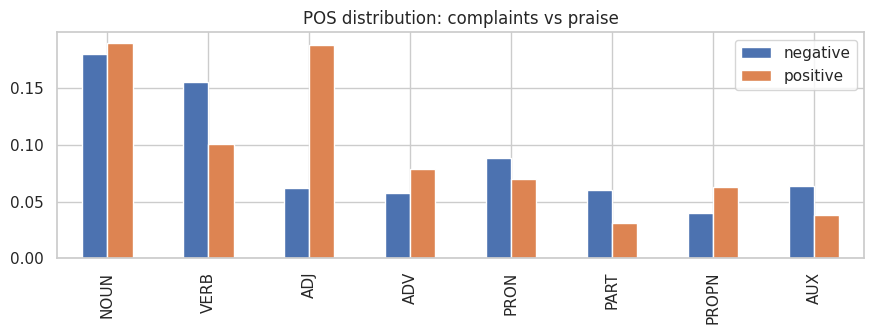

,aspect → opinion (complaints),count
0,work → not working,76
1,app → not work,33
2,open → not working,22
3,app → bad,19
4,login → not working,14
5,log → not working,14
6,know → not working,11
7,app → not open,11
8,experience → bad,11
9,app → useless,8


,Matcher rule: phrase,count
0,ERROR_MSG: error,53
1,ERROR_MSG: crashing,28
2,ERROR_MSG: something went wrong,15
3,ERROR_MSG: crashes,14
4,ERROR_MSG: failed,12
5,CANT_DO: can't log,7
6,CANT_DO: unable to login,5
7,CANT_DO: can't login,5
8,CANT_DO: can't use,5
9,CANT_DO: can't create,4


In [11]:
en = raw[raw.lang == "en"].copy()
en["label"] = en["rating"].map(config.rating_to_label)
docs = {lab: list(linguistic.nlp().pipe(en[en.label == lab]["text"].head(800))) for lab in ["negative", "positive"]}
pos = pd.DataFrame({lab: pd.Series(linguistic.pos_counts(d)) for lab, d in docs.items()}).fillna(0)
pos = (pos / pos.sum()).loc[["NOUN", "VERB", "ADJ", "ADV", "PRON", "PART", "PROPN", "AUX"]]
pos.plot.bar(figsize=(9, 3.5), title="POS distribution: complaints vs praise"); savefig("pos")
from collections import Counter
pairs = Counter(f"{a} → {o}" for d in docs["negative"] for a, o in linguistic.aspects(d))
matches = Counter(f"{lab}: {txt}" for d in docs["negative"] for lab, txt in linguistic.match_phrases(d) if lab != "ADV_ADJ_NOUN")
display(pd.DataFrame(pairs.most_common(15), columns=["aspect → opinion (complaints)", "count"]))
pd.DataFrame(matches.most_common(10), columns=["Matcher rule: phrase", "count"])

Complaints use more **verbs and particles** ("can't", "not", "doesn't open"): people describe failed actions.
Praise uses more **adjectives** ("easy", "great"). This is why the aspect rules include the negated-verb pattern.

## 5. N-grams: the phrases people repeat

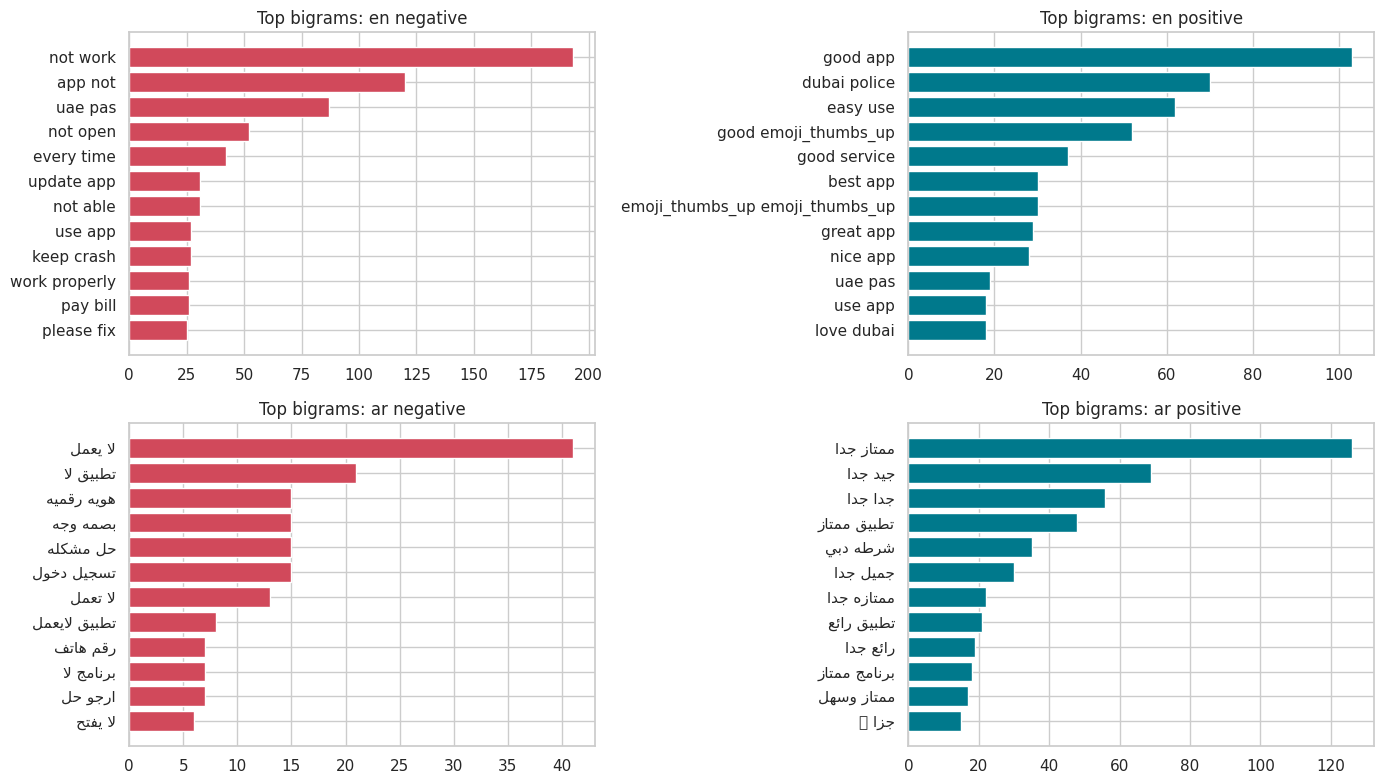

Top 1-grams in English complaints: [('not', 856), ('app', 570), ('work', 290), ('update', 206), ('time', 179), ('use', 164), ('pay', 144), ('try', 137)]
Top 3-grams in English complaints: [('app not work', 49), ('not work properly', 22), ('app not open', 18), ('uae pas not', 16), ('something go wrong', 15), ('login uae pas', 11), ('not user friendly', 11), ('app keep crash', 10)]


In [12]:
raw["label"] = raw["rating"].map(config.rating_to_label)
raw["tokens"] = [preprocess.tokens(t, l) for t, l in zip(raw.text, raw.lang)]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, lang in enumerate(["en", "ar"]):
    for j, lab in enumerate(["negative", "positive"]):
        sub = raw[(raw.lang == lang) & (raw.label == lab)]["tokens"]
        grams = linguistic.top_ngrams(sub, n=2, k=12)
        if grams:
            g = pd.DataFrame(grams, columns=["bigram", "n"])
            if lang == "ar":
                try:
                    from bidi.algorithm import get_display; import arabic_reshaper
                    g["bigram"] = g["bigram"].map(lambda s: get_display(arabic_reshaper.reshape(s)))
                except ImportError:
                    pass
            axes[i, j].barh(g["bigram"][::-1], g["n"][::-1], color="#d1495b" if lab == "negative" else "#00798c")
        axes[i, j].set_title(f"Top bigrams: {lang} {lab}")
savefig("ngrams")
for n in (1, 3):
    print(f"Top {n}-grams in English complaints:", linguistic.top_ngrams(raw[(raw.lang == 'en') & (raw.label == 'negative')]['tokens'], n=n, k=8))

## 6. Run the full NLP pipeline on every review
`cvoice/pipeline.py` applies, to each review: language detection → preprocessing → **sentiment** (routed: English
RoBERTa / Arabic CAMeLBERT / XLM-R for mixed) → **emotion** → **urgency score** → spaCy **aspects, relations, NER**
(English) and **CAMeLBERT NER** (Arabic) → **BGE-M3 embeddings** → **issue clustering** with LLM names.
Results are saved to `data/`, which is what the Streamlit app reads. On a T4 this takes a few minutes for ~7k reviews.

In [13]:
t0 = time.time()
df, X = pipeline.run(full=True)
R["n_reviews"] = len(df); R["pipeline_minutes"] = round((time.time() - t0) / 60, 1)
print(f"{len(df)} reviews analysed in {R['pipeline_minutes']} min; embeddings: {X.shape}")
df[["app", "lang", "rating", "sentiment", "emotion", "urgency", "issue_label", "text"]].head(8)

Language detection + preprocessing for 5365 reviews
Sentiment (RoBERTa for English, CAMeLBERT for Arabic, XLM-R for mixed)


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/165 [00:00<?, ?it/s]

Clustering 1703 complaints
  k=13 clusters; naming them with the LLM
  13/13 clusters named by the LLM
Done: 5271 reviews analysed -> /content/citizen-voice/data/enriched.parquet
5271 reviews analysed in 4.8 min; embeddings: (5271, 1024)


,app,lang,rating,sentiment,emotion,urgency,issue_label,text
0,UAE PASS,en,1,positive,neutral,2.0,Positive feedback,easy to use
1,UAE PASS,en,5,positive,neutral,0.7,None,Best and easy to use
2,UAE PASS,en,5,neutral,neutral,8.3,None,finigr
3,UAE PASS,en,5,positive,neutral,8.0,None,good
4,UAE PASS,en,4,positive,neutral,8.0,None,good
5,UAE PASS,en,5,positive,neutral,8.0,None,good
6,UAE PASS,en,5,positive,joy,0.4,None,great app great uae
7,UAE PASS,en,5,positive,joy,0.6,None,very good app


## 7. Text representations: BoW vs TF-IDF vs Word2Vec vs BGE-M3
A **fair comparison**: the same classifier (logistic regression) predicts the sentiment label (from stars) using
each representation; we also measure **precision@5**: for a review, how many of its 5 nearest neighbours share its
label. Train/test split is stratified by label **and** language, and it is reused for every model in the notebook.

In [14]:
train_idx, test_idx = evaluate.split(df)
train, test = df.loc[train_idx], df.loc[test_idx]
R["n_train"], R["n_test"] = len(train), len(test)

w2v_rows = []
for vs, win in [(50, 3), (100, 5), (200, 8)]:
    m = evaluate.train_word2vec(train["tokens"], vector_size=vs, window=win)
    V = evaluate.w2v_doc_vectors(m, df["tokens"].tolist())
    pred, _ = evaluate.classify(V, df["label"].values, train_idx, test_idx)
    w2v_rows.append({"vector_size": vs, "window": win, **evaluate.scores(test["label"], pred), "model": m})
w2v = pd.DataFrame(w2v_rows)
best_w2v = w2v.loc[w2v["macro_f1"].idxmax(), "model"]
display(w2v.drop(columns="model"))
for w in ["otp", "login", "تطبيق"]:
    if w in best_w2v.wv:
        print(w, "→", [x for x, _ in best_w2v.wv.most_similar(w, topn=6)])

,vector_size,window,accuracy,macro_f1
0,50,3,0.786,0.584
1,100,5,0.755,0.567
2,200,8,0.752,0.565


otp → ['email', 'receive', 'sm', 'address', 'digit', 'send']
login → ['upgrade', 'connect', 'id', 'guest', 'close', 'another']
تطبيق → ['برنامج', 'سريع', 'موقع', 'وصول', 'عمل', 'شي']


In [15]:
rep_table, reps = evaluate.compare_representations(df, X, train_idx, test_idx, best_w2v)
R["representations"] = rep_table.to_dict("records")
rep_table

,representation,dimensions,accuracy,macro_f1,precision@5
0,BoW,1819,0.843,0.611,0.771
1,TF-IDF (1-2 grams),3622,0.829,0.600,0.787
2,Word2Vec (trained here),50,0.786,0.584,0.792
3,BGE-M3 (pre-trained),1024,0.833,0.633,0.866


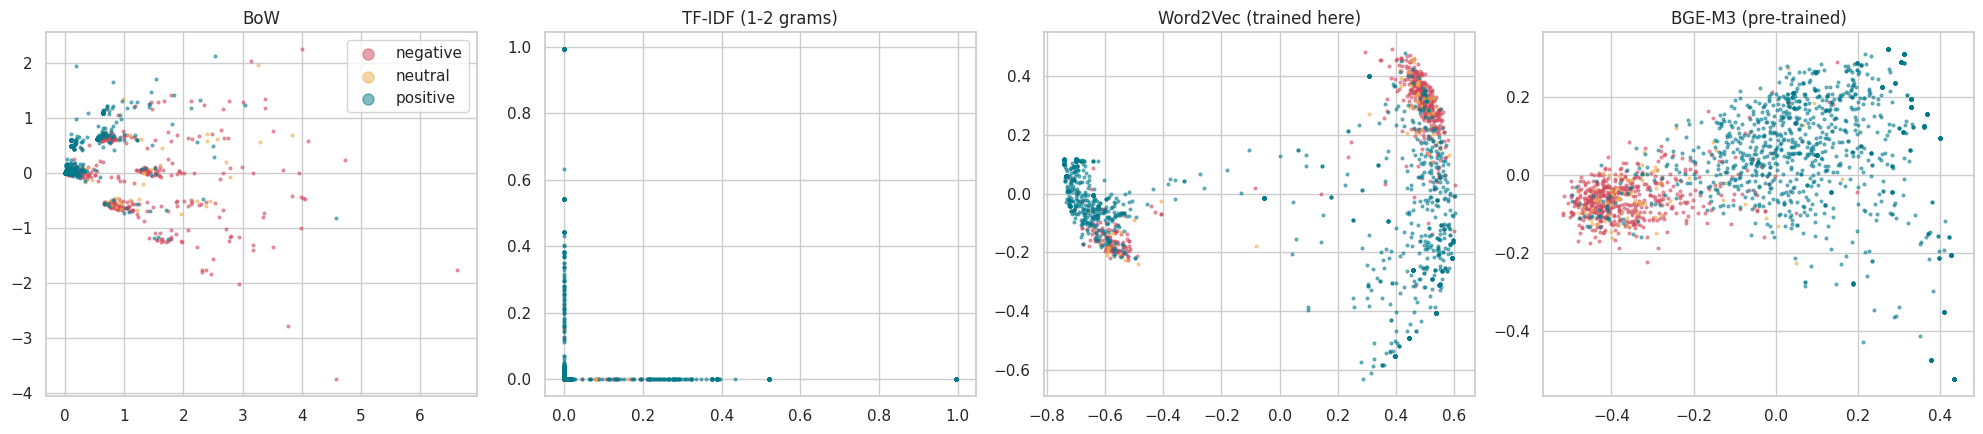

In [16]:
from sklearn.decomposition import PCA, TruncatedSVD
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sample = np.random.default_rng(0).choice(len(df), size=min(2000, len(df)), replace=False)
for ax, (name, M) in zip(axes, reps.items()):
    M = M[sample]
    P = (TruncatedSVD(2, random_state=0).fit_transform(M) if hasattr(M, "toarray") else PCA(2, random_state=0).fit_transform(M))
    for lab, col in [("negative", "#d1495b"), ("neutral", "#edae49"), ("positive", "#00798c")]:
        m = df["label"].values[sample] == lab
        ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, c=col, label=lab)
    ax.set_title(name)
axes[0].legend(markerscale=4); savefig("embeddings_pca")

### Cross-lingual retrieval test
The same question asked in English and in Arabic should retrieve **the same reviews**. TF-IDF cannot do this
(Arabic and English share no words); a multilingual embedding model maps both into one semantic space.

In [17]:
pairs = [("the OTP verification code does not arrive", "رمز التحقق لا يصل"),
         ("the app crashes after the update", "التطبيق يتوقف بعد التحديث"),
         ("face recognition does not work", "خاصية التعرف على الوجه لا تعمل"),
         ("payment failed but money was deducted", "فشل الدفع وتم خصم المبلغ"),
         ("excellent and easy to use app", "تطبيق ممتاز وسهل الاستخدام")]
tfv = evaluate.tfidf(evaluate.joined(train), evaluate.joined(df))[1]
X_tfidf = tfv.transform(evaluate.joined(df))
xl = evaluate.cross_lingual_test(df, pairs, models.embed, tfv, X_tfidf, X)
R["cross_lingual"] = xl.groupby("method")[["overlap@10", "arabic_share_for_en_query"]].mean().round(2).to_dict("index")
display(xl.groupby("method")[["overlap@10", "arabic_share_for_en_query"]].mean())
idx = search.ReviewIndex(df, X)
idx.search("the OTP verification code does not arrive", k=6)[["score", "app", "lang", "rating", "text"]]

,overlap@10,arabic_share_for_en_query
method,,
BGE-M3,0.36,0.2
TF-IDF,0.00,0.0


,score,app,lang,rating,text
13,0.836,UAE PASS,en,1,no receiving OTP
57,0.820,UAE PASS,en,1,I AM NOT GETTING OTP
581,0.787,UAE PASS,en,1,"no OTP is received, extremely bad app"
35,0.783,UAE PASS,en,1,did not get otp
246,0.782,UAE PASS,en,1,unable to sign up. didn't receive OTP. Please ...
1460,0.780,DubaiNow,en,1,Code not coming


## 8. Sentiment analysis: five approaches on the same test set
| Approach | Family (lecture 3) | Languages |
|---|---|---|
| VADER | lexicon / rule-based | English only |
| TF-IDF + logistic regression | classical machine learning, trained on our data | both |
| Routed pre-trained: RoBERTa (EN) + CAMeLBERT-DA (AR) | deep learning, pre-trained, used as is | both |
| XLM-RoBERTa sentiment | one multilingual pre-trained model | both |
| **XLM-R + LoRA (ours)** | **fine-tuned on our reviews** (section 9) | both |

Ground truth comes from the stars (1-2 negative, 3 neutral, 4-5 positive). This is a **weak label**: some people
write a positive text and give 1★, so 100% is impossible.

In [18]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
def vader_label(t):
    c = vader.polarity_scores(t)["compound"]
    return "positive" if c >= 0.05 else "negative" if c <= -0.05 else "neutral"

test = test.copy()
test["pred_vader"] = test["text"].map(vader_label)
pred_lr, _ = evaluate.classify(X_tfidf, df["label"].values, train_idx, test_idx)
test["pred_tfidf_lr"] = pred_lr
test["pred_routed"] = test["sentiment"]
multi = models.sentiment_hf(test["text"].tolist(), config.SENTIMENT_MULTI)
test["pred_xlmr"] = multi[config.LABELS].idxmax(axis=1).values

## 9. Fine-tuning: XLM-RoBERTa + LoRA (parameter-efficient)
*Pre-training* gave XLM-R general knowledge of 100 languages; *fine-tuning* adapts it to our task and domain
(government app complaints, Gulf dialect, OTP / Emirates ID vocabulary). With **LoRA** we freeze the 278M
pre-trained weights and train small low-rank matrices in the attention layers, under 1% of the parameters.

In [19]:
ft = finetune.train_lora(train, test, epochs=3)
R["lora_trainable_pct"] = round(100 * ft["trainable_params"] / ft["total_params"], 2)
R["lora_minutes"] = round(ft["minutes"], 1)
test["pred_lora"] = ft["y_pred"]
display(ft["history"])

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 1,182,723 / 279,228,678 (0.42%)
epoch 1: loss=0.9505 acc=0.885 macro-F1=0.592
epoch 2: loss=0.7433 acc=0.908 macro-F1=0.608
epoch 3: loss=0.7253 acc=0.899 macro-F1=0.615


,epoch,train_loss,accuracy,macro_f1
0,1,0.950512,0.885308,0.591509
1,2,0.743342,0.908057,0.607620
2,3,0.725334,0.898578,0.614934


,method,en accuracy,en macro_f1,all accuracy,all macro_f1,ar accuracy,ar macro_f1
0,VADER (lexicon),0.714,0.532,NaN,NaN,NaN,NaN
1,TF-IDF + LR,0.857,0.623,0.829,0.600,0.791,0.558
2,RoBERTa / CAMeLBERT (pre-trained),0.850,0.639,0.843,0.639,0.831,0.602
3,XLM-R (pre-trained),0.862,0.640,0.857,0.643,0.849,0.632
4,XLM-R + LoRA (fine-tuned),0.898,0.613,0.899,0.615,0.899,0.606


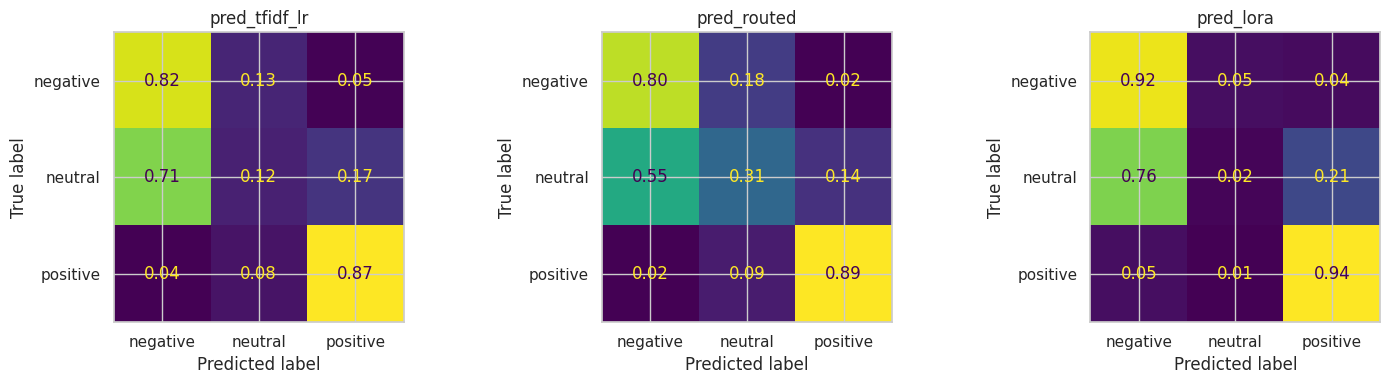

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
methods = {"VADER (lexicon)": "pred_vader", "TF-IDF + LR": "pred_tfidf_lr",
           "RoBERTa / CAMeLBERT (pre-trained)": "pred_routed", "XLM-R (pre-trained)": "pred_xlmr",
           "XLM-R + LoRA (fine-tuned)": "pred_lora"}
rows = []
for name, col in methods.items():
    s = evaluate.scores_by_lang(test, col)
    if name.startswith("VADER"):
        s = {"en": s.get("en")}
    rows.append({"method": name,
                 **{f"{k} {m}": v[m] for k, v in s.items() if v for m in ("accuracy", "macro_f1")}})
sent_table = pd.DataFrame(rows)
R["sentiment"] = sent_table.to_dict("records")
display(sent_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["pred_tfidf_lr", "pred_routed", "pred_lora"]):
    ConfusionMatrixDisplay.from_predictions(test["label"], test[col], labels=config.LABELS, ax=ax,
                                            colorbar=False, normalize="true", values_format=".2f")
    ax.set_title(col)
savefig("confusion")

**How to read this:** the general pre-trained models already work without any training, but the **fine-tuned**
model learns the domain (and the star-label convention) and usually wins on macro-F1, especially for Arabic.
The neutral class is the hardest for every method: 3★ reviews mix praise and complaints.

## 10. Emotion / mood detection
English: `j-hartmann/emotion-english-distilroberta-base` (Ekman's 6 emotions + neutral). Arabic: multilingual
zero-shot NLI (mDeBERTa) with the same labels. We also place each emotion on Russell's **valence-arousal**
circumplex: anger is negative + high arousal (urgent), sadness is negative + low arousal (disappointment).

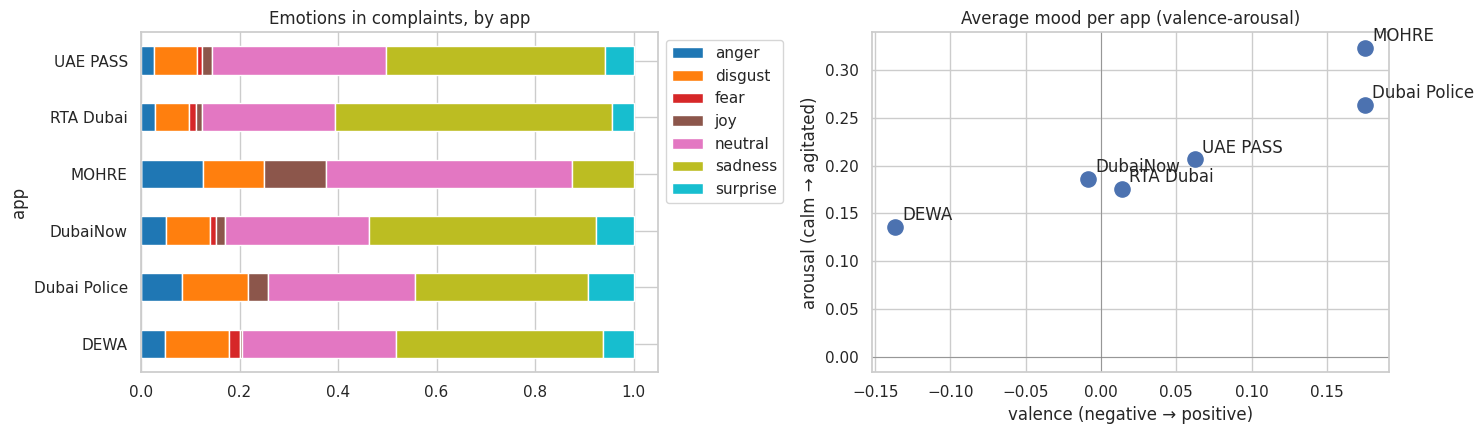

emotion,anger,disgust,fear,joy,neutral,sadness,surprise
rating,,,,,,,
1,0.05,0.11,0.01,0.02,0.30,0.46,0.06
2,0.03,0.02,0.01,0.02,0.37,0.50,0.05
3,0.01,0.02,0.01,0.09,0.49,0.30,0.07
4,0.00,0.00,0.00,0.28,0.48,0.20,0.03
5,0.00,0.01,0.00,0.47,0.44,0.05,0.02


In [21]:
neg = df[df["is_negative"] == 1]
emo_app = pd.crosstab(neg["app"], neg["emotion"], normalize="index")
VA = {"anger": (-0.6, 0.8), "disgust": (-0.7, 0.3), "fear": (-0.6, 0.6), "joy": (0.8, 0.5),
      "neutral": (0.0, 0.0), "sadness": (-0.7, -0.4), "surprise": (0.3, 0.8)}
df["valence"] = sum(df[e] * VA[e][0] for e in config.EMOTIONS)
df["arousal"] = sum(df[e] * VA[e][1] for e in config.EMOTIONS)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
emo_app.plot.barh(stacked=True, ax=ax[0], colormap="tab10"); ax[0].set_title("Emotions in complaints, by app")
ax[0].legend(bbox_to_anchor=(1, 1))
va = df.groupby("app")[["valence", "arousal"]].mean()
ax[1].scatter(va["valence"], va["arousal"], s=120)
for app, (v, a) in va.iterrows(): ax[1].annotate(app, (v, a), xytext=(5, 5), textcoords="offset points")
ax[1].axhline(0, c="grey", lw=.5); ax[1].axvline(0, c="grey", lw=.5)
ax[1].set_xlabel("valence (negative → positive)"); ax[1].set_ylabel("arousal (calm → agitated)")
ax[1].set_title("Average mood per app (valence-arousal)")
savefig("emotions")
R["anger_share_complaints"] = round((neg["emotion"] == "anger").mean(), 3)
R["sadness_share_complaints"] = round((neg["emotion"] == "sadness").mean(), 3)
R["emotion_by_rating"] = pd.crosstab(df["rating"], df["emotion"], normalize="index").round(2).to_dict("index")
pd.crosstab(df["rating"], df["emotion"], normalize="index").round(2)

## 11. Named Entity Recognition and relation extraction
Three NER systems: spaCy (English, statistical), CAMeLBERT-NER (Arabic, transformer) and an LLM with a structured
JSON prompt that also extracts **relations** (subject, relation, object) and app-specific types (feature,
error message, government service) that general NER models do not know.

In [22]:
en_ents = Counter(lab for ents in df[df.lang == "en"]["entities"] for _, lab in ents)
ar_ents = Counter(f"{w} ({lab})" for ents in df[df.lang == "ar"]["entities"] for w, lab in ents)
print("spaCy entity types (English):", en_ents.most_common(8))
print("Top CAMeLBERT entities (Arabic):", ar_ents.most_common(10))
svo = Counter(" | ".join(t) for lst in df[df.is_negative == 1]["svo"] for t in lst)
pd.DataFrame(svo.most_common(12), columns=["subject | verb | object (spaCy, complaints)", "count"])

spaCy entity types (English): [('ORG', 382), ('GPE', 250), ('CARDINAL', 250), ('DATE', 220), ('PERSON', 156), ('TIME', 41), ('PRODUCT', 23), ('ORDINAL', 23)]
Top CAMeLBERT entities (Arabic): [('دبي (LOC)', 86), ('الله (MISC)', 73), ('الامارات (LOC)', 13), ('الإمارات (LOC)', 7), ('الإمارات العربية المتحدة (LOC)', 4), ('RT (ORG)', 3), ('نو (MISC)', 3), ('ديو (PERS)', 3), ('السامسونج (MISC)', 2), ('الشارقة (LOC)', 2)]


,"subject | verb | object (spaCy, complaints)",count
0,i | use | app,9
1,i | use | it,4
2,it | show | error,4
3,app | not work | update,4
4,i | not do | anything,3
5,app | not work | uae,3
6,i | try | device,3
7,i | face | issue,3
8,app | have | issue,3
9,i | need | it,3


In [24]:
sample_ner = pd.concat([df[(df.is_negative == 1) & (df.lang == "en")].nlargest(8, "urgency"),
                        df[(df.is_negative == 1) & (df.lang == "ar")].nlargest(8, "urgency")])
if llm.available():
    ext = genai.extract_entities(sample_ner, batch=4)
    if len(ext):
        for col in ["feature", "issue_type", "entities", "relations"]:
            if col not in ext:
                ext[col] = None
        ext = ext[["review_id", "feature", "issue_type", "entities", "relations"]]
        classical = sample_ner[["review_id", "text", "entities"]].rename(columns={"entities": "classical_entities"})
        ext = ext.rename(columns={"entities": "llm_entities"}).merge(classical, on="review_id")
        ext["n classical"] = ext["classical_entities"].map(len)
        ext["n LLM"] = ext["llm_entities"].map(lambda e: len(e) if isinstance(e, list) else 0)
        R["ner_entities_per_review"] = {"classical": round(ext["n classical"].mean(), 2), "llm": round(ext["n LLM"].mean(), 2)}
        display(ext[["text", "feature", "issue_type", "llm_entities", "relations", "classical_entities"]].head(10))

,text,feature,issue_type,llm_entities,relations,classical_entities
0,One of the worst customer support services I h...,None,customer support,[],"[{'subject': 'user', 'relation': 'paid_for', '...","[[One, CARDINAL], [24 hours, TIME], [3 weeks l..."
1,This is crazy. I'm just about to pay the third...,payment,login/auth,"[{'text': 'Salik', 'type': 'ORG'}]","[{'subject': 'user', 'relation': 'attempted_to...","[[third, ORDINAL], [Salik, GPE]]"
2,"I think this is a scam app, I applied for a cr...",None,other,[],"[{'subject': 'user', 'relation': 'applied_for'...","[[24 hours, TIME]]"
3,The worst app I’ve ever seen; the app crashes ...,payment,crash/bug,[],"[{'subject': 'app', 'relation': 'crashes_on', ...","[[the morning, TIME]]"
4,Worst app ever.i reset my password more than 5...,password reset,login/auth,"[{'text': 'account is locked', 'type': 'ERROR_...","[{'subject': 'user', 'relation': 'cannot_reset...",[]
5,افشل واسوأ تطبيق ويتم الخصم من حسابك ولا تتم ا...,payment,payment,[],"[{'subject': 'user', 'relation': 'cannot_compl...",[]
6,اصبح خارب كل مره لان التحدبث الجديد خربه وغير ...,fines,crash/bug,[],"[{'subject': 'user', 'relation': 'cannot_searc...",[]
7,البرنامج غبي بنسبه للدفع,payment,performance,[],"[{'subject': 'app', 'relation': 'slow', 'objec...",[]
8,غير دقيق . دفعني سعر الخصم ولم يقم بدفع فاتورة...,payment,payment,[{'text': 'رقم المبلغ غير صحيح [Invalid amount...,"[{'subject': 'app', 'relation': 'incorrect_amo...",[]
9,تجربة سيئة جدآ قمت بدفع مخالفات على هذا التطبي...,NaN,NaN,NaN,NaN,[]


## 12. Automatic issue discovery
Complaints are clustered on their BGE-M3 embeddings (k-means; k chosen by **silhouette score**), each cluster is
described by **class-based TF-IDF** keywords, and the LLM writes a bilingual name. Because the embeddings are
multilingual, Arabic and English reports of the same problem fall in the **same** cluster.

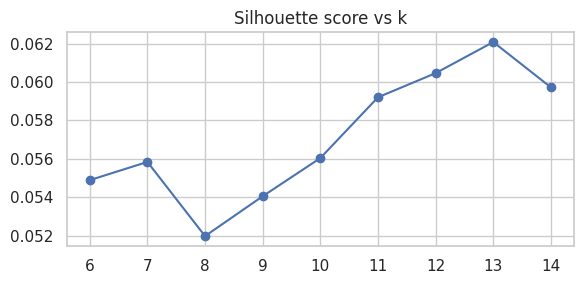

,id,label_en,label_ar,size,avg_rating,share_arabic,keywords
7,7,Parking payment issue,مشكلة في دفع المواقف,200,1.65,0.15,"[park, fine, not, app, rta, pay, car, get, pay..."
8,8,Poor customer service,خدمة عملاء سيئة,184,1.20,0.16,"[app, not, worst, service, bad, ever, time, تط..."
3,3,Payment failure,فشل في الدفع,172,1.45,0.12,"[pay, payment, card, bill, not, dewa, app, opt..."
1,1,Login problem,مشكلة في تسجيل الدخول,161,1.36,0.43,"[login, دخول, مشكله, تسجيل, not, account, لا, ..."
4,4,App launch failure,فشل تشغيل التطبيق,160,1.41,0.32,"[app, app not, not, تطبيق, work, open, not wor..."
12,12,Update malfunction,عطل بعد التحديث,144,1.53,0.14,"[update, not, app, version, work, update app, ..."
9,9,App crash on update,تطبيق يتطاير بعد التحديث,127,1.54,0.07,"[crash, update, keep, keep crash, every, app, ..."
11,11,App not working,التطبيق لا يعمل,124,1.46,0.44,"[not, لا, work, not work, open, يعمل, not open..."
0,0,Arabic language issue,مشكلة في اللغة العربية,114,1.75,0.65,"[dubai, ما, لغه, ناس, عربيه, ليش, برنامج, مش, ..."
10,10,UAE Pass login issue,مشكلة في دخول UAE Pass,104,1.57,0.02,"[uae, pas, uae pas, not, login, app, work, log..."


In [25]:
cl = topics.load()
R["n_clusters"] = cl["k"]
if cl["silhouette"]:
    pd.Series(cl["silhouette"]).plot(marker="o", figsize=(6, 3), title="Silhouette score vs k"); savefig("silhouette")
issues = pd.DataFrame([{k: c[k] for k in ["id", "label_en", "label_ar", "size", "avg_rating", "share_arabic", "keywords"]}
                       for c in cl["clusters"]]).sort_values("size", ascending=False)
R["issues"] = issues.head(8).drop(columns="keywords").to_dict("records")
R["mixed_language_clusters"] = int(((issues.share_arabic > 0.1) & (issues.share_arabic < 0.9)).sum())
issues

## 13. Release regression detector
For each app version: complaint rate vs the rest of that app's reviews (two-proportion z-test). We test dozens of
versions, so p-values are corrected with **Benjamini-Hochberg** (false discovery rate 5%); otherwise some versions
would be flagged by pure chance. A flag means "this release made things significantly worse", and the cluster that
grew the most says *what* broke.

65 versions tested; 15 have p < 0.05 before correction, 10 remain flagged after Benjamini-Hochberg


,app,version,reviews,neg_rate,baseline,lift,z,avg_rating,p,first_seen,top_growing_issue,q,flag,issue_that_grew
2,DEWA,10.3.6,20,0.950,0.511,0.439,3.87,1.35,0.0001,2026-07-22 07:45:24,4.0,0.0012,True,App launch failure
11,Dubai Police,7.0.5,25,0.200,0.069,0.131,2.51,4.20,0.0060,2026-02-07 10:47:20,9.0,0.0392,True,App crash on update
39,RTA Dubai,6.2.7,33,0.515,0.287,0.228,2.82,2.97,0.0024,2025-06-02 19:47:07,8.0,0.0223,True,Poor customer service
40,RTA Dubai,6.2.9,42,0.500,0.286,0.214,2.98,2.90,0.0015,2025-07-12 01:45:49,9.0,0.0190,True,App crash on update
42,RTA Dubai,6.3.6,40,0.475,0.287,0.188,2.55,3.02,0.0054,2025-10-16 14:59:57,8.0,0.0392,True,Poor customer service
45,RTA Dubai,6.4.2,43,0.628,0.280,0.348,4.89,2.35,0.0000,2026-04-11 09:31:25,10.0,0.0000,True,UAE Pass login issue
46,RTA Dubai,6.4.3,24,0.542,0.289,0.253,2.68,2.54,0.0037,2026-04-17 15:57:06,7.0,0.0298,True,Parking payment issue
48,RTA Dubai,6.4.6,33,0.515,0.287,0.228,2.82,2.94,0.0024,2026-06-02 19:59:05,1.0,0.0223,True,Login problem
49,RTA Dubai,6.4.8,27,0.778,0.281,0.496,5.58,1.85,0.0000,2026-08-26 05:00:40,4.0,0.0000,True,App launch failure
63,UAE PASS,6.9.1,142,0.352,0.227,0.125,3.20,3.49,0.0007,2026-08-31 07:18:42,1.0,0.0112,True,Login problem


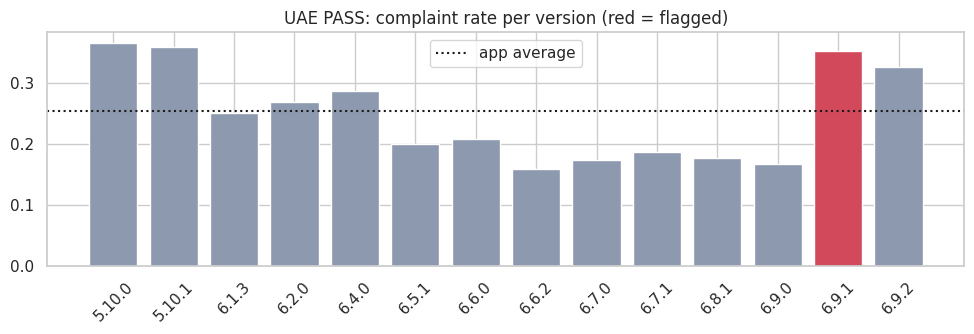

In [26]:
vt = regression.version_table(df)
names = {c["id"]: c["label_en"] for c in cl["clusters"]}
R["n_versions_tested"] = len(vt)
R["n_versions_p05"] = int((vt["p"] < 0.05).sum()) if len(vt) else 0
print(f"{len(vt)} versions tested; {int((vt['p'] < 0.05).sum()) if len(vt) else 0} have p < 0.05 before correction, "
      f"{int(vt['flag'].sum()) if len(vt) else 0} remain flagged after Benjamini-Hochberg")
if len(vt):
    vt["issue_that_grew"] = vt["top_growing_issue"].map(lambda c: names.get(int(c)) if pd.notna(c) else None)
    R["release_flags"] = vt[vt.flag][["app", "version", "reviews", "neg_rate", "baseline", "z", "q", "issue_that_grew"]].to_dict("records")
    display(vt[vt.flag] if vt.flag.any() else "No significant release regressions in this data.")
    top_app = vt.groupby("app")["reviews"].sum().idxmax()
    v = vt[vt.app == top_app]
    plt.figure(figsize=(10, 3.5))
    plt.bar(v["version"].astype(str), v["neg_rate"], color=np.where(v["flag"], "#d1495b", "#8d99ae"))
    plt.axhline(df[df.app == top_app]["is_negative"].mean(), ls=":", c="k", label="app average")
    plt.title(f"{top_app}: complaint rate per version (red = flagged)"); plt.xticks(rotation=45); plt.legend()
    savefig("regression")

## 14. Prompt engineering: three strategies
Same LLM, same reviews, only the **prompt** changes (lab: Prompt Engineering). Reviews are sent in batches of 15 to
respect the free-tier limits, and answers are cached on disk.

In [27]:
if llm.available():
    pe_sample = pd.concat([g.sample(min(len(g), 8), random_state=0) for _, g in test.groupby(["label", "lang"])])
    pe_rows = []
    for strat in genai.STRATEGIES:
        preds = pd.Series(genai.classify_with_prompt(pe_sample["text"].tolist(), strat), index=pe_sample.index)
        ok = preds.notna()
        if ok.sum() == 0:
            print(f"{strat}: no answers, left out of the table"); continue
        pe_rows.append({"strategy": strat, "coverage": round(ok.mean(), 2),
                        **evaluate.scores(pe_sample.loc[ok, "label"], preds[ok])})
    pe_rows.append({"strategy": "fine-tuned XLM-R + LoRA (same reviews)", "coverage": 1.0,
                    **evaluate.scores(pe_sample["label"], pe_sample["pred_lora"])})
    pe = pd.DataFrame(pe_rows); R["prompting"] = pe.to_dict("records"); R["llm_model"] = llm.last_model_used
    print("LLM:", llm.last_model_used, "| reviews:", len(pe_sample)); display(pe)
    print(genai.STRATEGIES["role_definitions"])

zero_shot: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.)
zero_shot: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.)
zero_shot: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.)
zero_shot: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.)
zero_shot: no answers, left out of the table
role_definitions: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.)
role_definitions: batch failed (OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still 

,strategy,coverage,accuracy,macro_f1
0,fine-tuned XLM-R + LoRA (same reviews),1.0,0.64,0.545


You are a senior customer-experience analyst at a UAE government digital services office.
Classify each app review (English or Arabic) by the reviewer's overall sentiment:
- negative: complaint, frustration, the app or service failed them
- neutral: mixed feelings, a question, a suggestion without clear emotion
- positive: satisfaction, praise or thanks
Focus on the overall experience, not individual words. Sarcasm counts as negative.
Return ONLY a JSON list of labels in the same order, e.g. ["negative","positive"].

{reviews}


## 15. "Ask Citizen Voice": RAG with a faithfulness check
1. **Retrieve** the 12 most relevant reviews with BGE-M3 (works for Arabic or English questions).
2. **Generate** an answer that may only use those reviews and must cite them ([R3]).
3. **Verify**: a second LLM call (LLM-as-a-judge) checks every claim against the cited reviews.

We compare against asking the LLM **without retrieval**, to show why grounding matters.

In [28]:
questions = ["Why are people unhappy with UAE PASS login?", "What payment problems do users report?",
             "ما هي أكثر مشاكل تطبيق الهوية والإقامة؟"]
rag_rows = []
if llm.available():
    for q in questions:
        try:
            out = search.ask(idx, q, k=12)
            no_ctx = llm.ask(f"Answer briefly (max 120 words): {q}")
            judge_noctx = search.judge(no_ctx, search._context(out["hits"])[0])
        except llm.LLMError as e:
            print("Skipped:", q, "|", str(e)[:200]); continue
        rag_rows.append({"question": q, "faithfulness_rag": out["judge"].get("faithfulness"),
                         "faithfulness_no_retrieval": judge_noctx.get("faithfulness"),
                         "citations": len(out["cited"]), "invalid_citations": len(out["invalid_citations"])})
        if "error" in out["judge"]:
            print("Judge failed:", out["judge"]["error"][:200])
        print("Q:", q, "\n", out["answer"], "\n", "-" * 80)
    if rag_rows:
        rag = pd.DataFrame(rag_rows); R["rag"] = rag.to_dict("records"); display(rag)

Skipped: Why are people unhappy with UAE PASS login? | OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.
Skipped: What payment problems do users report? | OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.
Skipped: ما هي أكثر مشاكل تطبيق الهوية والإقامة؟ | OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.


## 16. Bilingual replies and the executive briefing

In [29]:
if llm.available():
    for _, r in df[~df.has_reply].nlargest(2, "urgency").iterrows():
        try:
            rep = genai.draft_reply(r.to_dict())
        except llm.LLMError as e:
            print("Reply skipped:", str(e)[:200]); continue
        print(f"REVIEW ({r.app}, {r.rating}★, urgency {r.urgency}): {r.text[:200]}\nEN: {rep.get('en')}\nAR: {rep.get('ar')}\n")
    stats = {"reviews": len(df), "complaint_rate": R["share_negative"], "issues": R["issues"][:5],
             "release_alerts": R.get("release_flags", []), "anger_share_in_complaints": R["anger_share_complaints"]}
    try:
        print(genai.executive_briefing(stats))
    except llm.LLMError as e:
        print("Briefing skipped:", str(e)[:200])

Reply skipped: OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.
Reply skipped: OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.
Briefing skipped: OpenRouter daily free-model limit reached (resets at 00:00 UTC). Cached answers still work; adding $10 credit raises the limit to 1000/day.


## 17. Export results for the report, then launch the app
`results.json` and `report/results.tex` (LaTeX macros) contain every number; the figures are in `figures/`.
Download `report_assets.zip` and upload its content to your Overleaf project: the report reads the numbers
automatically, so they always match your run.

In [30]:
from cvoice import report_export
zpath = report_export.export(R)
print(open("report/results.tex").read()[:1200])
if IN_COLAB:
    from google.colab import files; files.download(str(zpath))

\newcommand{\NReviews}{5,271}
\newcommand{\AvgRating}{3.8}
\newcommand{\ShareNeg}{28\%}
\newcommand{\ShareAr}{42\%}
\newcommand{\MedianWords}{3}
\newcommand{\NClusters}{13}
\newcommand{\NTrain}{4216}
\newcommand{\NTest}{1055}
\newcommand{\LoraPct}{0.42}
\newcommand{\LoraMin}{1.1}
\newcommand{\AngerShare}{4\%}
\newcommand{\PipelineMin}{4.8}
\newcommand{\LLMModel}{recursive/flint-v1.0:free}
\newcommand{\MixedClusters}{11}
\newcommand{\NFlags}{10}
\newcommand{\BgeFone}{0.633}
\newcommand{\BgePfive}{0.866}
\newcommand{\TfidfAcc}{0.829}
\newcommand{\TfidfFone}{0.6}
\newcommand{\WvFone}{0.584}
\newcommand{\XLOverlap}{0.36}
\newcommand{\XLArShare}{20\%}
\newcommand{\VaderFone}{0.532}
\newcommand{\TfidfLrFone}{0.6}
\newcommand{\RoutedFone}{0.639}
\newcommand{\XlmrFone}{0.643}
\newcommand{\XlmrAcc}{0.857}
\newcommand{\LoraFone}{0.615}
\newcommand{\LoraAcc}{0.899}
\newcommand{\LoraArAcc}{0.899}
\newcommand{\LoraArFone}{0.606}
\newcommand{\SadShare}{46\%}
\newcommand{\NVersions}{65}
\newcommand{\

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
if IN_COLAB:
    sh("wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared")
    subprocess.Popen("streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1", shell=True)
    time.sleep(8)
    tunnel = subprocess.Popen("./cloudflared tunnel --url http://localhost:8501 --no-autoupdate",
                              shell=True, stderr=subprocess.PIPE, text=True)
    import re
    for line in tunnel.stderr:
        m = re.search(r"https://[\w-]+\.trycloudflare\.com", line)
        if m:
            print("🌍 Open the app:", m.group(0)); break

> wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared
ok
🌍 Open the app: https://baltimore-halifax-bits-excel.trycloudflare.com
